# 1.0 Where does the financial pressure sit?

A trust board or regional finance director's first question: **how many trusts are in deficit, in which
sectors, and is it getting worse?** This notebook answers it in three views: the share of trusts in
deficit, the size of the combined surplus or deficit, and the spread of operating margins in the latest
year.

**Data:** NHS England Trust Accounts Consolidation (TAC), read from `analysis/data/` (exported from the
`nhs_gold` views by `python/reporting/export_for_analysis.py`). Annual, actuals only, £000s in the data and
£m on the charts. Operating surplus is the TAC SoCI line `SCI0140A` as each trust reported it. It is not
NHS England's adjusted financial performance measure, which excludes impairments and some transfers.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make analysis/nhs_analysis.py importable whether this runs from the repo root or this folder
ANALYSIS_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "nhs_analysis.py").exists()
                    or (p / "analysis" / "nhs_analysis.py").exists())
ANALYSIS_DIR = ANALYSIS_DIR if (ANALYSIS_DIR / "nhs_analysis.py").exists() else ANALYSIS_DIR / "analysis"
sys.path.insert(0, str(ANALYSIS_DIR))

import nhs_analysis as nhs

nhs.set_style()
pd.options.display.float_format = "{:,.1f}".format

In [2]:
ty = nhs.load_trust_year()
years = nhs.financial_years(ty)
first_year, latest_year = years[0], years[-1]
print(f"{ty.org_code.nunique()} trusts, {len(ty)} trust-years, {first_year} to {latest_year}")

215 trusts, 633 trust-years, 2021/22 to 2023/24


## 1.1 Share of trusts in operating deficit

The share of trusts in each sector reporting an operating deficit, by year. A bar per sector keeps each
sector's colour fixed across every chart in this folder.

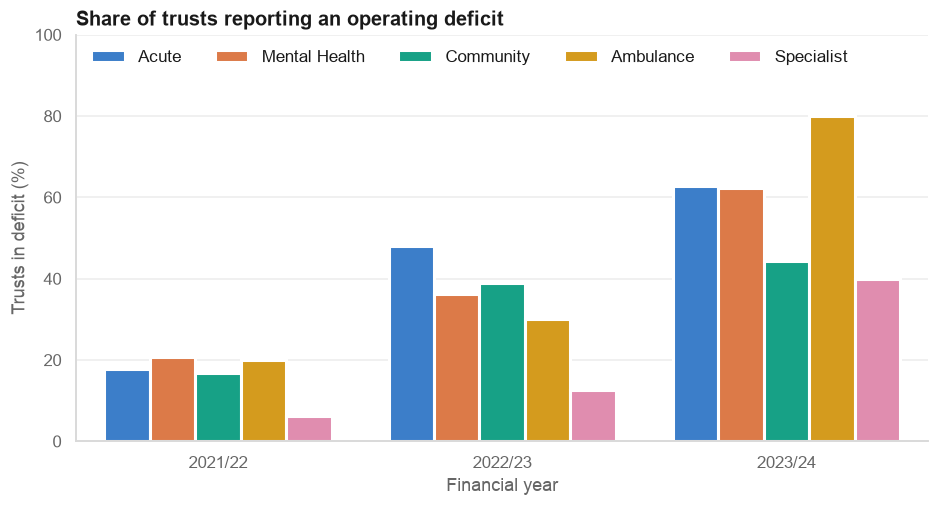

financial_year,2021/22,2022/23,2023/24
sector,,,
Acute,17.9,47.9,62.7
Mental Health,20.8,36.2,62.2
Community,16.7,38.9,44.4
Ambulance,20.0,30.0,80.0
Specialist,6.2,12.5,40.0


In [3]:
deficit_share = (
    ty.groupby(["financial_year", "sector"], observed=True)
      .agg(trusts=("org_code", "size"), in_deficit=("is_deficit", "sum"))
      .assign(pct_in_deficit=lambda d: d.in_deficit / d.trusts * 100)
      .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=deficit_share, x="financial_year", y="pct_in_deficit", hue="sector",
            hue_order=nhs.SECTOR_ORDER, palette=nhs.SECTOR_COLOURS, ax=ax,
            edgecolor="white", linewidth=2)
ax.set(title="Share of trusts reporting an operating deficit",
       xlabel="Financial year", ylabel="Trusts in deficit (%)", ylim=(0, 100))
ax.legend(title=None, ncols=5, loc="upper left", bbox_to_anchor=(0, 1.0))
plt.show()

deficit_share.pivot(index="sector", columns="financial_year", values="pct_in_deficit")

## 1.2 Combined operating surplus or deficit

Adding the trusts together shows the size of the problem in money. Acute trusts are far larger than the
other sectors, so each sector gets its own scale. Red bars are deficits, blue bars are surpluses.

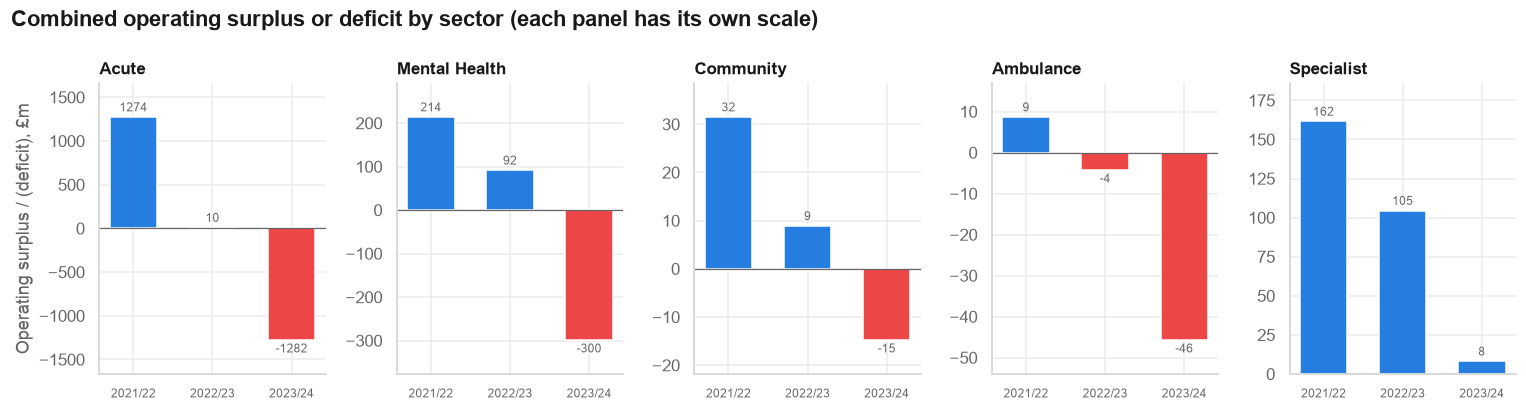

financial_year,2021/22,2022/23,2023/24
sector,,,
Acute,"1,274.3",9.9,"-1,282.2"
Mental Health,214.1,91.7,-299.7
Community,31.5,8.9,-14.9
Ambulance,8.7,-4.4,-45.8
Specialist,161.6,104.5,8.1


In [4]:
totals = (
    ty.groupby(["sector", "financial_year"], observed=True)["operating_surplus_000s"].sum()
      .reset_index()
      .assign(operating_surplus_m=lambda d: nhs.to_m(d.operating_surplus_000s))
)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.8), sharey=False)
for ax, sector in zip(axes, nhs.SECTOR_ORDER):
    d = totals[totals.sector == sector]
    colours = [nhs.DEFICIT if v < 0 else nhs.SURPLUS for v in d.operating_surplus_m]
    bars = ax.bar(d.financial_year, d.operating_surplus_m, color=colours, width=0.6)
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=2, color=nhs.TEXT_SECONDARY)
    ax.margins(y=0.15)
    ax.axhline(0, color=nhs.TEXT_SECONDARY, linewidth=0.8)
    ax.set_title(sector, fontsize=11)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Operating surplus / (deficit), £m")
fig.suptitle("Combined operating surplus or deficit by sector (each panel has its own scale)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

totals.pivot(index="sector", columns="financial_year", values="operating_surplus_m")

## 1.3 Spread of operating margins in the latest year

A sector total can hide a few very large deficits. The box shows the middle half of trusts, and each dot
is one trust. Dots left of the zero line are in deficit.

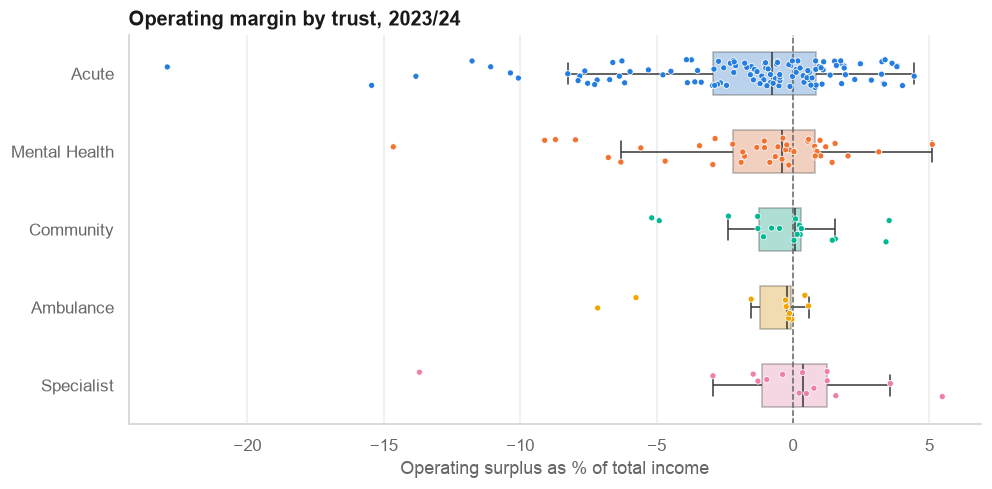

,count,min,25%,50%,75%,max
sector,,,,,,
Acute,118.0,-22.9,-2.9,-0.8,0.8,4.4
Mental Health,45.0,-14.7,-2.2,-0.4,0.8,5.1
Community,18.0,-5.2,-1.2,0.1,0.3,3.5
Ambulance,10.0,-7.2,-1.2,-0.2,-0.1,0.6
Specialist,15.0,-13.7,-1.1,0.4,1.3,5.5


In [5]:
latest = ty[ty.financial_year == latest_year]

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.boxplot(data=latest, y="sector", x="operating_margin_pct", order=nhs.SECTOR_ORDER,
            hue="sector", palette=nhs.SECTOR_COLOURS, legend=False, ax=ax,
            fliersize=0, width=0.55, boxprops={"alpha": 0.35})
sns.stripplot(data=latest, y="sector", x="operating_margin_pct", order=nhs.SECTOR_ORDER,
              hue="sector", palette=nhs.SECTOR_COLOURS, legend=False, ax=ax,
              size=4, jitter=0.18, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=nhs.TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.set(title=f"Operating margin by trust, {latest_year}",
       xlabel="Operating surplus as % of total income", ylabel=None)
plt.show()

latest.groupby("sector", observed=True)["operating_margin_pct"].describe()[["count", "min", "25%", "50%", "75%", "max"]]

## 1.4 The ten largest deficits in the latest year

The trusts behind the sector totals, ranked by the size of their operating deficit. EBITDA margin is
shown alongside: a trust with a large operating deficit but a positive EBITDA margin has usually booked a
large impairment (a non-cash write-down), rather than running out of money day to day.

In [6]:
(latest.nsmallest(10, "operating_surplus_000s")
   .assign(operating_surplus_m=lambda d: nhs.to_m(d.operating_surplus_000s))
   [["organisation_name", "sector", "operating_surplus_m", "operating_margin_pct", "ebitda_margin_pct"]]
   .rename(columns={"organisation_name": "Trust", "sector": "Sector",
                    "operating_surplus_m": "Operating surplus / (deficit), £m",
                    "operating_margin_pct": "Operating margin %",
                    "ebitda_margin_pct": "EBITDA margin %"})
   .reset_index(drop=True))

,Trust,Sector,"Operating surplus / (deficit), £m",Operating margin %,EBITDA margin %
0,University Hospitals Sussex NHS Foundation Trust,Acute,-153.4,-10.1,4.0
1,East Kent Hospitals University NHS Foundation ...,Acute,-145.1,-15.4,-9.1
2,St George's University Hospitals NHS Foundatio...,Acute,-95.8,-7.8,5.8
3,West Suffolk NHS Foundation Trust,Acute,-91.1,-22.9,3.4
4,Northern Care Alliance NHS Foundation Trust,Acute,-85.0,-4.8,0.4
5,Guy's & St Thomas' NHS Foundation Trust,Acute,-66.4,-2.3,4.9
6,Doncaster and Bassetlaw Teaching Hospitals NHS...,Acute,-66.0,-11.8,-0.8
7,Nottingham University Hospitals NHS Trust,Acute,-64.9,-3.9,0.4
8,Mersey Care NHS Foundation Trust,Mental Health,-60.2,-8.0,4.4
9,Lancashire Teaching Hospitals NHS Foundation T...,Acute,-58.1,-7.2,1.0
